# Step 4: predicting arousal with signal delays

Steps 1–3 measured delays **between** signals (Resp → heart ≈ 0.7 s, heart → skin ≈ 2.5 s from Maroua, no brain → skin link).
To choose *when* to read each signal for prediction, we also need each signal's delay **relative to the video**.

**4.1 Mean response of each signal to the video**, then **4.2 prediction** with naive vs delay-aware windows, **4.3 SCR features and normalisation relative to rest**
- Signals: heart rate (HR), skin conductance (GSR), pupil diameter, respiration.
- Trial: black "Prepare yourself" screen at −5 s, video 0–10 s, rating sliders after 10 s (only the video onset is marked).
- Each signal is z-scored per participant over the session, epoched from −5 to +15 s, and baseline-corrected on −5…−4 s
  (first second of the black screen, before any response to it can start).
- Questions: (1) when does each signal respond, (2) in which time window do high- and low-arousal videos differ,
  (3) does the gap between the skin and heart responses match Maroua's heart → skin delay (~2.5 s)?

Data: Maroua's 20 participants, day 1, emotion-video, PREPROCESSED. Arousal: high / low third of each participant's own ratings
(`tertile_cuts`, provisional until Micha's split).

In [10]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt
from scipy.stats import t as t_dist

ROOT = Path.cwd().parent if Path.cwd().name == "latence" else Path.cwd()
sys.path.insert(0, str(ROOT / "latence"))
from physio_utils import FS, load_bdf, bdf_path, load_metadata, notch, r_peaks, rr_suspects, hr_series, resp_clean, resp_polarity
from hep_utils import tertile_cuts

DATA = Path(os.environ.get("HABS_DATA", ROOT.parent / "habs_data"))
VERSION = "PREPROCESSED"
PARTICIPANTS = ("P001 P017 P020 P086 P097 P126 P128 P129 P131 P137 "
                "P174 P186 P187 P194 P201 P217 P219 P308 P310 P459").split()
SIGNALS = ["HR", "GSR", "pupil", "resp"]
FG = 20.0                       # Hz, common grid
EPOCH = (-5.0, 15.0)            # s around video onset
BASE = (-5.0, -4.0)             # s, first second of the black screen
T = np.arange(int(EPOCH[0] * FG), int(EPOCH[1] * FG)) / FG
print("data:", DATA, "(exists)" if DATA.is_dir() else "(MISSING: set HABS_DATA)")

data: /Users/hugotrebert/Documents/4A/Habs-Hackathon/habs_data (exists)


In [11]:
def lowpass(x, hz, fs):
    return sosfiltfilt(butter(2, hz, fs=fs, output="sos"), x)


def pupil_clean(sig):
    # Mean of both eyes on the 1000 Hz timeline (stored at ~166 Hz: NaN between samples) -> blinks removed -> 20 Hz.
    x = sig[["pupildiameter_le", "pupildiameter_ri"]].mean(axis=1).to_numpy().copy()
    x[(x < 1.5) | (x > 9)] = np.nan                                     # implausible diameters (mm)
    s = pd.Series(x).interpolate(limit_area="inside")
    med = s.rolling(int(FS), center=True, min_periods=1).median()
    bad = (s - med).abs() > 0.4                                         # sharp drops = blinks
    bad = bad.rolling(int(0.2 * FS), center=True, min_periods=1).max().astype(bool)   # ±100 ms around them
    s[bad] = np.nan
    missing = s.isna().mean()
    s = s.interpolate(limit_area="inside").bfill().ffill().to_numpy()
    return lowpass(s, 4.0, FS)[::int(FS / FG)], missing


def load_signals(subj, day=1, task="emotion-video"):
    # The four signals on a 20 Hz grid (native units) + quality info.
    _, sig, _ = load_bdf(bdf_path(task, subj, day, data=DATA, version=VERSION))
    n = len(sig)
    pk = r_peaks(notch(sig.ECG.to_numpy()), verbose=False)
    _, hr = hr_series(pk, n, fs_out=FG)
    gsr = lowpass(sig.GSR.to_numpy(), 1.0, FS)[::int(FS / FG)]
    resp = resp_clean(sig.Resp.to_numpy())
    pol = resp_polarity(resp)
    resp = (-resp if pol["fall_shorter"] else resp)[::int(FS / FG)]    # inspiration up
    pupil, pupil_missing = pupil_clean(sig)
    m = min(len(hr), len(gsr), len(resp), len(pupil))
    out = {"HR": hr[:m], "GSR": gsr[:m], "pupil": pupil[:m], "resp": resp[:m]}
    qc = {"participant": subj, "duration_s": m / FG, "rr_suspect_pct": 100 * rr_suspects(pk).mean(),
          "hr_median": np.median(hr), "gsr_range_uS": np.percentile(gsr, 99) - np.percentile(gsr, 1),
          "pupil_missing_pct": 100 * pupil_missing, "resp_inspiration_down": pol["fall_shorter"]}
    return out, qc


def onsets_by_marker(subj, day=1):
    # Video onset (s, in the emotion-video segment) for each marker_id.
    m = load_metadata(subj, day, data=DATA, version=VERSION)
    seg = m["dataset_export"]["segments"]["emotion-video"]
    t0, dur = seg["metadata_time_origin_s"], seg["duration_s"]
    return {e["marker_id"]: e["onset_s"] - t0 for e in m["events"]
            if e.get("trial_type") == "emotion_video" and 0 <= e["onset_s"] - t0 < dur}


def epoch(x, onset_s):
    # Signal from EPOCH[0] to EPOCH[1] around onset, minus its mean on BASE.
    i0 = int(round((onset_s + EPOCH[0]) * FG))
    seg = x[i0:i0 + len(T)]
    return seg - seg[(T >= BASE[0]) & (T < BASE[1])].mean()

In [12]:
# Load + epoch (≈ 2–3 min for 20 participants)
labels = pd.read_csv(DATA / "labels_train.csv", na_values=["TESTSUBJECT"])
labels = labels[(labels.day == 1) & labels.rating_arousal.notna() & (labels.flagged_outliers != 1)]

ep = {s: [] for s in SIGNALS}       # z per participant (4.1)
ep_raw = {s: [] for s in SIGNALS}   # native units (4.3)
sig20, rows, qcs = {}, [], []
for p in PARTICIPANTS:
    x, qc = load_signals(p)
    qcs.append(qc)
    sig20[p] = x
    z = {s: (v - v.mean()) / v.std() for s, v in x.items()}
    onset_of = onsets_by_marker(p)
    lab = labels[labels.participant_id == p]
    lo, hi = tertile_cuts(lab.rating_arousal)
    for r in lab.itertuples():
        v = onset_of.get(int(r.start_marker))
        if v is None or v + EPOCH[0] < 0 or (v + EPOCH[1]) * FG > len(z["HR"]):
            continue
        for s in SIGNALS:
            ep[s].append(epoch(z[s], v))
            ep_raw[s].append(epoch(x[s], v))
        rows.append({"participant": p, "onset_s": v, "arousal": r.rating_arousal,
                     "level": "high" if r.rating_arousal >= hi else "low" if r.rating_arousal <= lo else "mid"})
trials = pd.DataFrame(rows)
ep = {s: np.array(v) for s, v in ep.items()}
ep_raw = {s: np.array(v) for s, v in ep_raw.items()}
qc = pd.DataFrame(qcs).set_index("participant")

# Exclusions per signal (participant level)
EXCLUDE = {"HR": qc.index[qc.rr_suspect_pct > 10].tolist(),
           "GSR": qc.index[qc.gsr_range_uS < 0.05].tolist(),       # flat sensor (step 3)
           "pupil": qc.index[qc.pupil_missing_pct > 30].tolist(),
           "resp": []}
print(f"{len(trials)} rated trials, {trials.participant.nunique()} participants")
print("excluded:", EXCLUDE)
print(qc.round(2))

Channel metadata: P001_day-1_task-emotion-video_multimodal.record_map
Gaze: stored 166 Hz, effective 166.358 Hz, onset 0.001 s
Channel metadata: P017_day-1_task-emotion-video_multimodal.record_map
Gaze: stored 139 Hz, effective 138.601 Hz, onset 0.005 s
Channel metadata: P020_day-1_task-emotion-video_multimodal.record_map
Gaze: stored 180 Hz, effective 179.999 Hz, onset 0.003 s
Channel metadata: P086_day-1_task-emotion-video_multimodal.record_map
Gaze: stored 135 Hz, effective 134.789 Hz, onset 0.004 s
Channel metadata: P097_day-1_task-emotion-video_multimodal.record_map
Gaze: stored 177 Hz, effective 176.906 Hz, onset 0.001 s
Channel metadata: P126_day-1_task-emotion-video_multimodal.record_map
Gaze: stored 182 Hz, effective 182.296 Hz, onset 0.000 s
Channel metadata: P128_day-1_task-emotion-video_multimodal.record_map
Gaze: stored 179 Hz, effective 179.313 Hz, onset 0.002 s
Channel metadata: P129_day-1_task-emotion-video_multimodal.record_map
Gaze: stored 186 Hz, effective 185.707 Hz

### 4.1a Mean response to the video
Grand average over participants (each participant first averaged over all their rated trials), ± SEM across participants.
Grey: black screen (−5…0 s); the video runs 0–10 s; ratings start at 10 s (their duration varies).

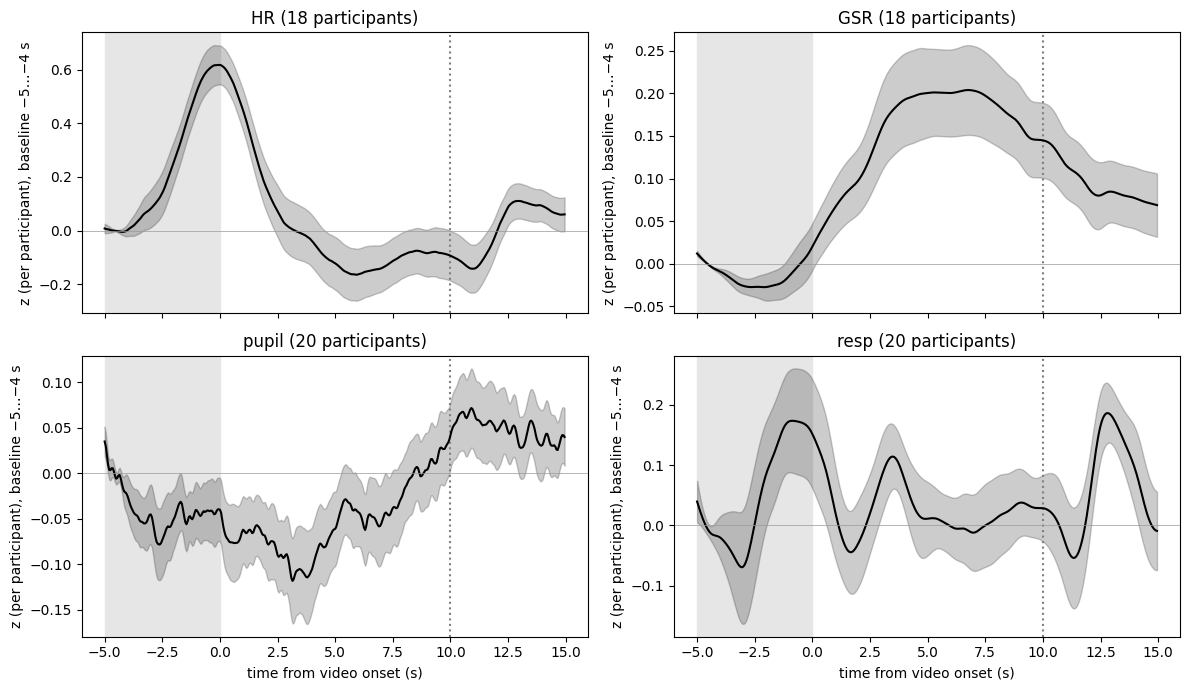

In [13]:
def participant_means(s, level=None):
    # (participants, time) mean epoch per participant, for one arousal level or all trials.
    keep = ~trials.participant.isin(EXCLUDE[s]) & (True if level is None else trials.level == level)
    d = trials[keep]
    return d.participant.unique(), np.array([ep[s][d.index[d.participant == p]].mean(axis=0) for p in d.participant.unique()])


UNITS = "z (per participant), baseline −5…−4 s"
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, s in zip(axes.flat, SIGNALS):
    _, m = participant_means(s)
    mu, se = m.mean(0), m.std(0, ddof=1) / np.sqrt(len(m))
    ax.axvspan(-5, 0, color="0.9"); ax.axvline(10, color="0.5", ls=":")
    ax.plot(T, mu, color="k"); ax.fill_between(T, mu - se, mu + se, color="k", alpha=0.2)
    ax.axhline(0, color="0.6", lw=0.5)
    ax.set_title(f"{s} ({len(m)} participants)"); ax.set_ylabel(UNITS)
for ax in axes[1]:
    ax.set_xlabel("time from video onset (s)")
plt.tight_layout(); plt.show()

### 4.1b High vs low arousal
For each participant: mean of the high-third trials minus mean of the low-third trials. Group test at each time point
(t-test across participants), corrected for the many time points with a **cluster permutation test**
(sign flips of each participant's difference curve, 5 000 draws): a cluster of consecutive significant points is kept
if its summed t is larger than 95 % of the largest clusters obtained by chance.

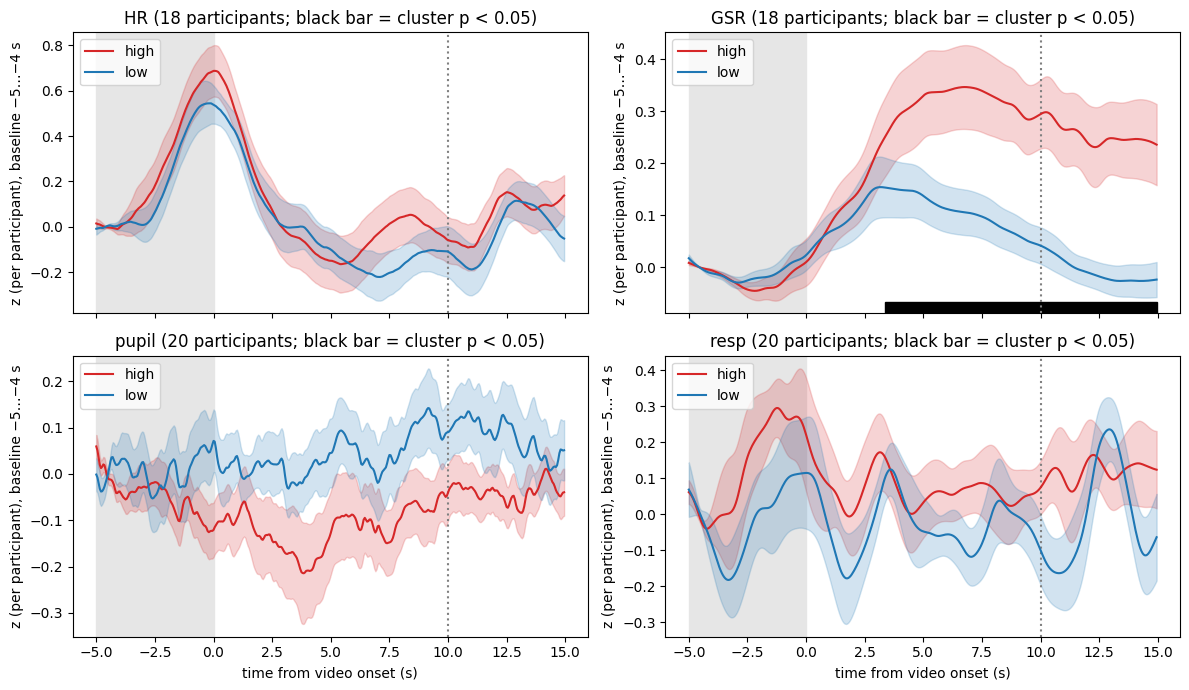

signal  from_s  to_s       sign  cluster_t_sum     p  participants
   GSR    3.35 14.95 high > low          847.6 0.000            18
 pupil   -0.05  0.05 high < low           -6.5 0.531            20
 pupil    4.10  4.40 high < low          -15.2 0.399            20
 pupil    9.20  9.45 high < low          -13.1 0.425            20
  resp   -2.55 -1.75 high > low           39.4 0.271            20
  resp    6.80  7.35 high > low           28.6 0.426            20
  resp   10.20 10.70 high > low           25.7 0.468            20


In [14]:
def clusters(tvals, thr):
    # Runs of consecutive |t| > thr with the same sign: list of (start, stop, mass).
    out, i = [], 0
    while i < len(tvals):
        if abs(tvals[i]) > thr:
            j = i
            while j < len(tvals) and abs(tvals[j]) > thr and np.sign(tvals[j]) == np.sign(tvals[i]):
                j += 1
            out.append((i, j, tvals[i:j].sum()))
            i = j
        else:
            i += 1
    return out


def cluster_test(d, n_perm=5000, seed=0):
    # d: (participants, time) differences. Returns t curve and clusters with permutation p-values.
    n = len(d)
    tstat = lambda x: x.mean(0) / (x.std(0, ddof=1) / np.sqrt(n))
    thr = t_dist.ppf(0.975, n - 1)
    t_obs = tstat(d)
    rng = np.random.default_rng(seed)
    null = np.array([max([abs(c[2]) for c in clusters(tstat(d * rng.choice([-1, 1], size=(n, 1))), thr)], default=0)
                     for _ in range(n_perm)])
    return t_obs, [(T[a], T[b - 1], m, (null >= abs(m)).mean()) for a, b, m in clusters(t_obs, thr)]


fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
res = []
for ax, s in zip(axes.flat, SIGNALS):
    ph, hi_m = participant_means(s, "high")
    pl, lo_m = participant_means(s, "low")
    both = np.intersect1d(ph, pl)
    hi_m, lo_m = hi_m[np.isin(ph, both)], lo_m[np.isin(pl, both)]
    t_obs, cl = cluster_test(hi_m - lo_m)
    ax.axvspan(-5, 0, color="0.9"); ax.axvline(10, color="0.5", ls=":")
    for m, c, lab in [(hi_m, "tab:red", "high"), (lo_m, "tab:blue", "low")]:
        mu, se = m.mean(0), m.std(0, ddof=1) / np.sqrt(len(m))
        ax.plot(T, mu, color=c, label=lab); ax.fill_between(T, mu - se, mu + se, color=c, alpha=0.2)
    for a, b, mass, p in cl:
        if p < 0.05:
            ax.axvspan(a, b, ymin=0, ymax=0.04, color="k")
        res.append({"signal": s, "from_s": a, "to_s": b, "sign": "high > low" if mass > 0 else "high < low",
                    "cluster_t_sum": round(mass, 1), "p": p, "participants": len(both)})
    ax.set_title(f"{s} ({len(both)} participants; black bar = cluster p < 0.05)"); ax.set_ylabel(UNITS)
    ax.legend(loc="upper left")
for ax in axes[1]:
    ax.set_xlabel("time from video onset (s)")
plt.tight_layout(); plt.show()
clusters_table = pd.DataFrame(res)
print(clusters_table.round(3).to_string(index=False))

### 4.1c Latency of each response and heart → skin cross-check
The HR response is a fast acceleration that peaks at video onset, i.e. a response to the black screen / "Continue" click (5 s earlier);
the skin responds with a slower rise. To compare their timing, we use the **speed** of the GSR rise (its slope, the phasic part)
rather than its level, and compare it with HR:
- **peak times**: HR peak (−5…3 s) and GSR slope peak (−5…10 s), per participant and on the group average;
- **cross-correlation** of HR with the GSR slope (`latence`, sign +1, ±5 s) on −5…10 s.
Maroua measured a heart → skin delay of ~2.5 s on the continuous signals; if the evoked responses give the same, the delay is real.

participant  HR_peak_s  GSR_slope_peak_s  gap_s  xcorr_lag_s    r
       P001       0.45              2.60   2.15         2.40 0.87
       P020       0.85             -4.05  -4.90        -2.40 0.38
       P086      -2.15             -2.25  -0.10        -2.30 0.67
       P126      -2.15             -1.05   1.10         0.00 0.48
       P128      -0.50              7.25   7.75        -0.55 0.53
       P129      -0.85             -0.25   0.60         0.00 0.84
       P131       0.25             -0.05  -0.30        -0.30 0.48
       P137      -1.20              3.20   4.40         3.95 0.64
       P174       0.65              4.95   4.30         2.75 0.45
       P186       1.45              6.60   5.15         1.60 0.47
       P194      -0.40              0.00   0.40         0.85 0.44
       P201       0.05              2.95   2.90         2.85 0.85
       P217      -0.95             -1.00  -0.05         0.60 0.74
       P219      -1.35              9.75  11.10         5.00 0.15
       P30

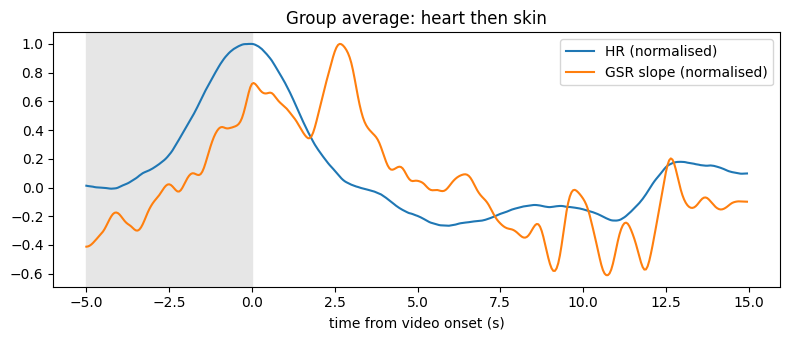

In [15]:
from physio_utils import latence

win = (T >= -5) & (T < 10)
ph, hr_m = participant_means("HR")
pg, gsr_m = participant_means("GSR")
rows = []
for p in np.intersect1d(ph, pg):
    h, g = hr_m[list(ph).index(p)], gsr_m[list(pg).index(p)]
    slope = np.gradient(g) * FG
    t_h = T[T < 3][np.argmax(h[T < 3])]
    t_g = T[T < 10][np.argmax(slope[T < 10])]
    lag, r = latence(h[win], slope[win], FG, max_lag_s=5, sign=+1)
    rows.append({"participant": p, "HR_peak_s": t_h, "GSR_slope_peak_s": t_g, "gap_s": t_g - t_h, "xcorr_lag_s": lag, "r": r})
hs = pd.DataFrame(rows)
print(hs.round(2).to_string(index=False))
print(f"per participant: gap median {hs.gap_s.median():+.2f} s (IQR {hs.gap_s.quantile(.25):+.2f} to {hs.gap_s.quantile(.75):+.2f}), "
      f"cross-correlation median {hs.xcorr_lag_s.median():+.2f} s (IQR {hs.xcorr_lag_s.quantile(.25):+.2f} to {hs.xcorr_lag_s.quantile(.75):+.2f})")

gh, gs = hr_m.mean(0), np.gradient(gsr_m.mean(0)) * FG
lag, r = latence(gh[win], gs[win], FG, max_lag_s=5, sign=+1)
print(f"group average: HR peak {T[T < 3][np.argmax(gh[T < 3])]:+.2f} s, GSR slope peak {T[T < 10][np.argmax(gs[T < 10])]:+.2f} s, "
      f"cross-correlation lag {lag:+.2f} s (r = {r:.2f})")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.axvspan(-5, 0, color="0.9")
ax.plot(T, gh / gh.max(), label="HR (normalised)")
ax.plot(T, gs / gs.max(), label="GSR slope (normalised)")
ax.set_xlabel("time from video onset (s)"); ax.legend(); ax.set_title("Group average: heart then skin")
plt.tight_layout(); plt.show()

**Observations 4.1** (numbers from a full run on 25 November; 707 rated trials, 20 participants; HR without P187 and P310, whose ECG gives > 10 % suspect RR intervals; GSR without P017 and P097, flat sensor)
- **Each signal has its own timing**:
  - **HR** accelerates during the black screen and peaks right at video onset (response to the black screen / "Continue" click), then slows down below baseline during the video.
  - **GSR** starts rising around video onset, is steepest at +2.7 s and plateaus from ~5 s.
  - **Respiration**: an inhalation during the black screen; nothing systematic during the video.
  - **Pupil**: slow constriction during the video, then dilation after it (probably the luminance of the videos and of the rating screen).
- **Only the skin separates high from low arousal**: GSR higher for high-arousal videos from **+3.4 s to the end of the window (+15 s)** (cluster p < 0.001, 18 participants). This matches step 3.2c (SCRs starting 1–11 s after onset) and shows that the difference **lasts beyond the end of the video**, into the rating period.
- **No arousal effect for HR, pupil or respiration** (no cluster p < 0.05). The pupil tends to be *smaller* for high arousal (the opposite of the expected dilation): probably video luminance, which we do not control.
- **Heart → skin cross-check: partial**. On the group average, the GSR slope peaks 2.7 s after the HR peak (cross-correlation: +1.9 s, r = 0.77), compatible with Maroua's ~2.5 s. But per participant it is unstable (gap median +1.6 s, IQR −0.1 to +4.6 s), and the GSR slope has two bumps (around 0 s and +2.7 s: responses to the black screen and to the video are mixed).

**Consequences for 4.2 (prediction)**: read the skin on ~3–15 s (not 0–10 s); in this time-locked view, HR, pupil and respiration carry no arousal information, so they would need other features (e.g. size of the HR slowdown, pupil corrected for luminance) or should be dropped.

**Limits**: 20 participants; provisional high / low split; pupil not corrected for luminance; one mean curve per participant is noisy for latencies.

## 4.2 — Does reading each signal at the right time improve prediction?

Task: classify each rated video as **high vs low arousal** (thirds of each participant's own ratings; middle third left out),
**leave-one-participant-out** (the model never sees the test participant), scored by the **AUC within each test participant**.
Model: logistic regression (simple and readable).

Features = mean of each signal (epochs of 4.1: z per participant, baseline −5…−4 s) over a time window. Before the model,
each feature is z-scored **within each participant over all their videos, without the ratings**: this is the "relative to the
person, no labels needed" normalisation that a new participant also allows.

Compared feature sets:
| set | signals | windows |
|---|---|---|
| naive, 4 signals | HR, GSR, pupil, resp | 0–10 s (the video) |
| naive, each signal alone | one signal | 0–10 s |
| skin, Maroua's lag | GSR | 2–12 s (video shifted by the ~2 s heart → skin delay) |
| skin, window learned | GSR | best window chosen **inside each training fold** (start 0–5 s, end 8–15 s) |
| 4 signals, skin window learned | HR, pupil, resp 0–10 s + GSR learned window | |

The skin window is chosen on the training participants only: choosing it from 4.1 (which used all participants)
and then testing on the same participants would be circular.

Controls: (1) the same pipeline with ratings shuffled within each participant (200 draws) gives the chance level of the
mean AUC; (2) the comparison between sets is paired across participants (Wilcoxon).

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from scipy.stats import wilcoxon

# Participants with all four signals usable, so that every set is tested on the same people
PRED = [p for p in trials.participant.unique() if not any(p in EXCLUDE[s] for s in SIGNALS)]
d42 = trials[trials.participant.isin(PRED)].copy()
print(f"{len(PRED)} participants, {len(d42)} rated videos, "
      f"{(d42.level == 'high').sum()} high / {(d42.level == 'low').sum()} low / {(d42.level == 'mid').sum()} middle")


def window_mean(s, a, b, idx, epochs=None):
    # Mean of signal s on [a, b[ s for the trials idx.
    m = (T >= a) & (T < b)
    return (ep if epochs is None else epochs)[s][idx][:, m].mean(axis=1)


def features(spec, d, norm="videos"):
    # spec: list of (signal, start, end), or (column of `trials`,) for trial-level features (4.3).
    # norm = "videos": z-scored within participant over all their videos (no labels used);
    #        "none": native units; "rest": native units / the participant's resting-state SD (4.3).
    cols = []
    for item in spec:
        if len(item) == 1:
            x, s = trials.loc[d.index, item[0]].to_numpy(float), "GSR"
        else:
            s = item[0]
            x = window_mean(*item, d.index, epochs=None if norm == "videos" else ep_raw)
        if norm == "rest":
            x = x / d.participant.map(lambda p: REST_SD.loc[p, s]).to_numpy()
        cols.append(x)
    X = pd.DataFrame(np.column_stack(cols), index=d.index)
    if norm == "videos":
        X = X.groupby(d.participant).transform(lambda c: (c - c.mean()) / c.std() if c.std() > 0 else c * 0)
    return X.to_numpy()


GSR_WINDOWS = [(a, b) for a in range(0, 6) for b in range(8, 16) if b - a >= 4]


def best_gsr_window(d, norm="videos"):
    # Window whose GSR mean best separates high from low in d (median AUC across participants).
    lab = d.level != "mid"
    scores = {}
    for a, b in GSR_WINDOWS:
        x = features([("GSR", a, b)], d, norm)[:, 0]
        dd = pd.DataFrame({"p": d.participant, "x": x, "y": d.level == "high"})[lab.to_numpy()]
        scores[(a, b)] = dd.groupby("p").apply(lambda g: roc_auc_score(g.y, g.x), include_groups=False).median()
    return max(scores, key=scores.get)


def loso(spec_fn, d, level=None, norm="videos", scale=False):
    # Leave-one-participant-out. spec_fn(train_df) -> spec. Returns AUC per test participant and the specs used.
    level = d.level if level is None else level
    aucs, used = {}, []
    for p in d.participant.unique():
        tr, te = d[d.participant != p], d[d.participant == p]
        ltr, lte = level[tr.index], level[te.index]
        spec = spec_fn(tr.assign(level=ltr))
        used.append(spec)
        Xtr, Xte = features(spec, tr, norm), features(spec, te, norm)
        if scale:   # across-participant standardisation, fitted on the training participants only
            mu, sd = Xtr.mean(0), Xtr.std(0)
            Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd
        ktr, kte = (ltr != "mid").to_numpy(), (lte != "mid").to_numpy()
        model = LogisticRegression().fit(Xtr[ktr], ltr[ktr] == "high")
        aucs[p] = roc_auc_score(lte[kte] == "high", model.predict_proba(Xte[kte])[:, 1])
    return pd.Series(aucs), used


NAIVE = {s: (s, 0, 10) for s in SIGNALS}
SETS = {
    "naive, 4 signals": lambda tr: list(NAIVE.values()),
    **{f"naive, {s} alone": (lambda tr, s=s: [NAIVE[s]]) for s in SIGNALS},
    "skin, Maroua's lag (2-12 s)": lambda tr: [("GSR", 2, 12)],
    "skin, window learned": lambda tr: [("GSR", *best_gsr_window(tr))],
    "4 signals, skin window learned": lambda tr: [NAIVE["HR"], NAIVE["pupil"], NAIVE["resp"], ("GSR", *best_gsr_window(tr))],
}
auc, windows = {}, {}
for name, fn in SETS.items():
    auc[name], used = loso(fn, d42)
    windows[name] = used
auc = pd.DataFrame(auc)
learned = pd.Series([s[0][1:] for s in windows["skin, window learned"]]).value_counts()
print("skin windows learned in the folds (start, end):", dict(learned))

16 participants, 569 rated videos, 198 high / 177 low / 194 middle
skin windows learned in the folds (start, end): {(5, 12): np.int64(8), (0, 14): np.int64(8)}


                                mean AUC  median AUC AUC > 0.5  p vs 0.5 (Wilcoxon)
naive, 4 signals                   0.583       0.598     13/16                0.018
naive, HR alone                    0.475       0.500      7/16                0.397
naive, GSR alone                   0.558       0.580     11/16                0.026
naive, pupil alone                 0.548       0.578      9/16                0.105
naive, resp alone                  0.537       0.540     13/16                0.051
skin, Maroua's lag (2-12 s)        0.575       0.596     11/16                0.016
skin, window learned               0.583       0.590     11/16                0.009
4 signals, skin window learned     0.611       0.625     13/16                0.003
chance level of the mean AUC (shuffled ratings): 95th percentile = 0.563
skin, Maroua's lag (2-12 s) vs naive GSR alone: diff +0.017, p = 0.039; vs naive, 4 signals: diff -0.008, p = 0.865
skin, window learned vs naive GSR alone: diff +0.025, p

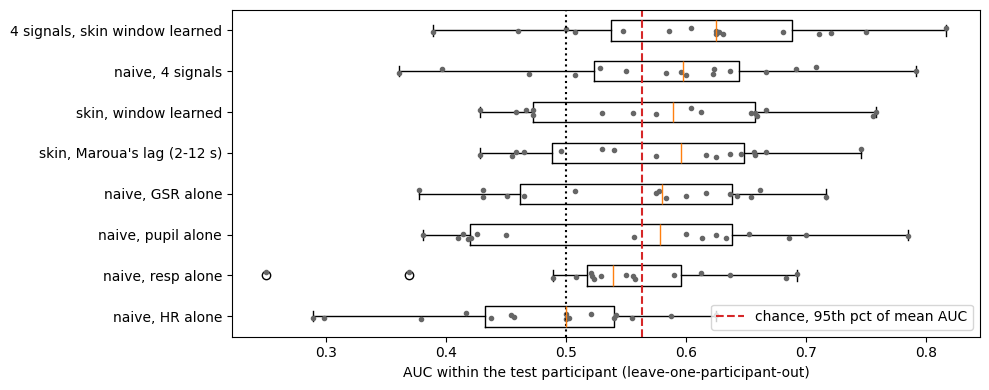

In [17]:
# Chance level: ratings shuffled within each participant, same pipeline (naive sets only: the learned window is slow)
rng = np.random.default_rng(0)
N_NULL = 200
null = {name: [] for name in ["naive, 4 signals", "skin, Maroua's lag (2-12 s)"]}
for _ in range(N_NULL):
    shuffled = d42.groupby("participant")["level"].transform(lambda l: pd.Series(rng.permutation(l.to_numpy()), index=l.index))
    for name in null:
        null[name].append(loso(SETS[name], d42, level=shuffled)[0].mean())
null = {k: np.array(v) for k, v in null.items()}
null_all = np.concatenate(list(null.values()))

table = pd.DataFrame({
    "mean AUC": auc.mean(), "median AUC": auc.median(),
    "AUC > 0.5": [f"{(auc[c] > 0.5).sum()}/{len(auc)}" for c in auc],
    "p vs 0.5 (Wilcoxon)": [wilcoxon(auc[c] - 0.5).pvalue for c in auc],
})
print(table.round(3).to_string())
print(f"chance level of the mean AUC (shuffled ratings): 95th percentile = {np.percentile(null_all, 95):.3f}")

ref = "naive, 4 signals"
for c in ["skin, Maroua's lag (2-12 s)", "skin, window learned", "4 signals, skin window learned"]:
    print(f"{c} vs naive GSR alone: diff {(auc[c] - auc['naive, GSR alone']).mean():+.3f}, "
          f"p = {wilcoxon(auc[c], auc['naive, GSR alone']).pvalue:.3f}; vs {ref}: diff {(auc[c] - auc[ref]).mean():+.3f}, "
          f"p = {wilcoxon(auc[c], auc[ref]).pvalue:.3f}")

fig, ax = plt.subplots(figsize=(10, 4))
order = auc.mean().sort_values().index
ax.boxplot([auc[c] for c in order], vert=False, tick_labels=order)
for i, c in enumerate(order, start=1):
    ax.plot(auc[c], np.full(len(auc), i) + rng.uniform(-0.1, 0.1, len(auc)), "o", color="0.4", ms=3)
ax.axvline(0.5, color="k", ls=":"); ax.axvline(np.percentile(null_all, 95), color="tab:red", ls="--", label="chance, 95th pct of mean AUC")
ax.set_xlabel("AUC within the test participant (leave-one-participant-out)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Observations 4.2** (full run on 25 November; 16 participants with all four signals usable, 375 high / low videos)
- **Chance level** of the mean AUC (ratings shuffled within participants): 95th percentile = 0.563. Only four sets are above it:
  naive 4 signals (0.583), skin with Maroua's lag 2–12 s (0.575), skin window learned (0.583), and **4 signals with the skin window learned (0.611, 13/16 participants above 0.5)**.
- **Reading the skin later helps a little**: GSR alone goes from 0.558 (0–10 s) to 0.575 (2–12 s, p = 0.039) and 0.583 (window learned in each fold, p = 0.029).
  With the other three signals, the learned skin window gives 0.611 against 0.583 for the naive windows (p = 0.017). Gains of 0.02–0.03 AUC.
- **The learned skin window is unstable**: half of the folds choose 5–12 s, the other half 0–14 s; the AUC changes little between windows.
  The useful message is "later than 0–10 s", not a precise window.
- **HR alone is at chance** (0.475), as expected from 4.1. Pupil (0.548) and respiration (0.537) alone are below the chance threshold but
  still add a little in the 4-signal model.
- These AUCs are of the same order as Maroua's (0.576 → 0.601 with the skin shifted by 2 s), with a much simpler model and the same conclusion.

**Limits**: 16 participants; several comparisons on the same data (the p-values are not corrected); provisional high / low split;
mean-over-window features only (no SCR count or amplitude, no HR slowdown size).

## 4.3 — SCR features and normalisation relative to rest

**(a) SCR features.** Step 3.2c showed that SCRs starting 1–11 s after video onset are more frequent and larger for high arousal.
We add two trial-level features (same detector as step 3: GSR low-passed at 1 Hz, peaks of prominence ≥ 0.02 µS, spike artefacts removed):
`scr_any` (at least one SCR starting 1–11 s after onset) and `scr_amp` (largest amplitude among them, 0 if none).

**(b) Normalisation.** For a new person, the features must be put on a common scale without their ratings. Three options:
- **none**: native units (bpm, µS, mm, a.u.), baseline-corrected;
- **rest**: native units divided by the participant's own variability (SD) at rest: resting-state segment, eyes-open part (0–30 s) for the pupil;
- **videos**: z-scored over all the participant's videos (what 4.2 does; it needs the whole session of the new person, still without ratings).

In all three, the features are then standardised across participants with the training participants' mean and SD only.
Participants: those of 4.2 with a usable resting-state (P308 has none; P459's GSR is flat at rest).

In [18]:
def scr_detect(g, fs=FG, min_amp=0.02, max_rise=5.0):
    # SCRs (onset_s, peak_s, amp_uS, artefact); same detector as step 3 (hugo_brain_skin.ipynb).
    from scipy.signal import find_peaks
    pk, _ = find_peaks(g, prominence=min_amp)
    rows, prev = [], 0
    for b in pk:
        lo = max(prev, b - int(max_rise * fs))
        a = lo + np.argmin(g[lo:b + 1])
        prev = b
        amp = g[b] - g[a]
        if amp < min_amp or a == b or g[a] <= 1.001:
            continue
        drop = g[b] - g[min(b + int(fs), len(g) - 1)]
        rows.append((a / fs, b / fs, amp, (b - a) / fs < 1.0 and drop > 0.5 * amp))
    return pd.DataFrame(rows, columns=["onset_s", "peak_s", "amp_uS", "artefact"])


trials["scr_any"], trials["scr_amp"] = 0.0, 0.0
for p in trials.participant.unique():
    if p in EXCLUDE["GSR"]:          # flat sensor: no SCR possible
        continue
    s = scr_detect(sig20[p]["GSR"])
    s = s[~s.artefact.astype(bool)]
    for i in trials.index[trials.participant == p]:
        v = trials.at[i, "onset_s"]
        w = s[(s.onset_s >= v + 1) & (s.onset_s < v + 11)]
        trials.at[i, "scr_any"] = float(len(w) > 0)
        trials.at[i, "scr_amp"] = w.amp_uS.max() if len(w) else 0.0
print(trials[trials.participant.isin(PRED)].groupby("level")[["scr_any", "scr_amp"]].mean().round(3))

SKIN = lambda tr, norm="videos": [("GSR", *best_gsr_window(tr, norm))]
SCR = [("scr_any",), ("scr_amp",)]
OTHERS = [NAIVE["HR"], NAIVE["pupil"], NAIVE["resp"]]
SETS43 = {
    "SCR features alone": lambda tr: SCR,
    "skin window learned + SCR": lambda tr: SKIN(tr) + SCR,
    "4 signals, skin window learned + SCR": lambda tr: OTHERS + SKIN(tr) + SCR,
}
for name, fn in SETS43.items():
    auc[name], _ = loso(fn, d42)
ref = "4 signals, skin window learned"
rows = []
for c in ["skin, window learned", ref, *SETS43]:
    rows.append({"set": c, "mean AUC": auc[c].mean(), "AUC > 0.5": f"{(auc[c] > 0.5).sum()}/{len(auc)}",
                 "p vs 0.5": wilcoxon(auc[c] - 0.5).pvalue,
                 f"diff vs '{ref}'": (auc[c] - auc[ref]).mean(),
                 "p (paired)": wilcoxon(auc[c], auc[ref]).pvalue if c != ref else np.nan})
print(pd.DataFrame(rows).set_index("set").round(3).to_string())

       scr_any  scr_amp
level                  
high     0.343    0.102
low      0.288    0.031
mid      0.330    0.046
                                      mean AUC AUC > 0.5  p vs 0.5  diff vs '4 signals, skin window learned'  p (paired)
set                                                                                                                     
skin, window learned                     0.583     11/16     0.009                                    -0.028       0.485
4 signals, skin window learned           0.611     13/16     0.003                                     0.000         NaN
SCR features alone                       0.555      8/16     0.124                                    -0.056       0.088
skin window learned + SCR                0.578     13/16     0.016                                    -0.033       0.231
4 signals, skin window learned + SCR     0.602     13/16     0.008                                    -0.009       0.552


In [19]:
# Resting-state variability of each signal, per participant
from physio_utils import task_windows
rest = []
for p in PRED:
    try:
        x, q = load_signals(p, task="resting-state")
    except FileNotFoundError:
        print(p, ": no resting-state")
        continue
    eyes_open = slice(0, int(30 * FG))
    rest.append({"participant": p, "HR": x["HR"].std(), "GSR": x["GSR"].std(), "resp": x["resp"].std(),
                 "pupil": x["pupil"][eyes_open].std(), "gsr_range_uS": q["gsr_range_uS"], "rr_suspect_pct": q["rr_suspect_pct"]})
REST_SD = pd.DataFrame(rest).set_index("participant")
print(REST_SD.round(3))
REST_OK = REST_SD.index[(REST_SD.gsr_range_uS >= 0.05) & (REST_SD.rr_suspect_pct <= 10)].tolist()
d43 = d42[d42.participant.isin(REST_OK)]
print(f"{len(REST_OK)} participants with a usable rest: {REST_OK}")

Channel metadata: P001_day-1_task-resting-state_multimodal.record_map
Gaze: stored 166 Hz, effective 166.358 Hz, onset 0.005 s
Channel metadata: P020_day-1_task-resting-state_multimodal.record_map
Gaze: stored 180 Hz, effective 179.999 Hz, onset 0.000 s
Channel metadata: P086_day-1_task-resting-state_multimodal.record_map
Gaze: stored 135 Hz, effective 134.789 Hz, onset 0.000 s
Channel metadata: P126_day-1_task-resting-state_multimodal.record_map
Gaze: stored 182 Hz, effective 182.296 Hz, onset 0.005 s
Channel metadata: P128_day-1_task-resting-state_multimodal.record_map
Gaze: stored 179 Hz, effective 179.313 Hz, onset 0.001 s
Channel metadata: P129_day-1_task-resting-state_multimodal.record_map
Gaze: stored 186 Hz, effective 185.707 Hz, onset 0.004 s
Channel metadata: P131_day-1_task-resting-state_multimodal.record_map
Gaze: stored 173 Hz, effective 173.297 Hz, onset 0.005 s
Channel metadata: P137_day-1_task-resting-state_multimodal.record_map
Gaze: stored 125 Hz, effective 124.854 Hz

                                                    mean AUC AUC > 0.5  p vs 0.5  diff vs none  p vs none
set                                  normalisation                                                       
4 signals, naive 0-10 s              none              0.577     11/13     0.033         0.000        NaN
                                     rest              0.559      9/13     0.054        -0.018      0.305
                                     videos            0.578     11/13     0.026         0.001      0.635
4 signals, skin window learned + SCR none              0.602      9/13     0.021         0.000        NaN
                                     rest              0.570      9/13     0.057        -0.032      0.110
                                     videos            0.589     10/13     0.027        -0.013      0.685
rest vs videos (best set): diff -0.019, p = 0.685


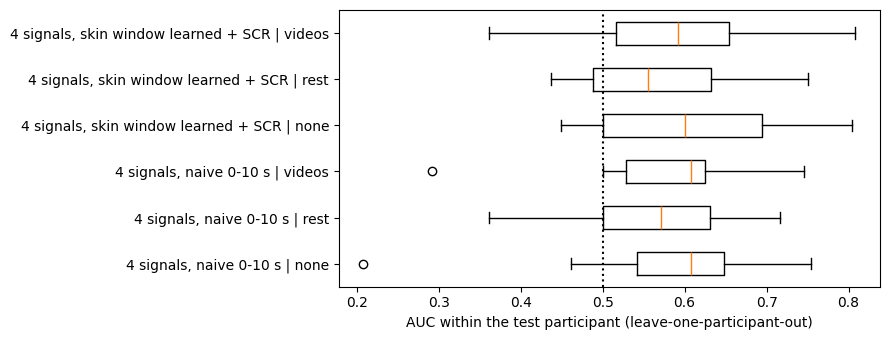

In [20]:
# Same models under the three normalisations, same participants
NORM_SETS = {
    "4 signals, naive 0-10 s": lambda tr, norm: list(NAIVE.values()),
    "4 signals, skin window learned + SCR": lambda tr, norm: OTHERS + SKIN(tr, norm) + SCR,
}
auc43 = {}
for set_name, fn in NORM_SETS.items():
    for norm in ["none", "rest", "videos"]:
        auc43[(set_name, norm)], _ = loso(lambda tr: fn(tr, norm), d43, norm=norm, scale=True)
auc43 = pd.DataFrame(auc43)
rows = []
for set_name in NORM_SETS:
    for norm in ["none", "rest", "videos"]:
        a = auc43[(set_name, norm)]
        rows.append({"set": set_name, "normalisation": norm, "mean AUC": a.mean(), "AUC > 0.5": f"{(a > 0.5).sum()}/{len(a)}",
                     "p vs 0.5": wilcoxon(a - 0.5).pvalue,
                     "diff vs none": (a - auc43[(set_name, "none")]).mean(),
                     "p vs none": wilcoxon(a, auc43[(set_name, "none")]).pvalue if norm != "none" else np.nan})
print(pd.DataFrame(rows).set_index(["set", "normalisation"]).round(3).to_string())
r, v = auc43[("4 signals, skin window learned + SCR", "rest")], auc43[("4 signals, skin window learned + SCR", "videos")]
print(f"rest vs videos (best set): diff {(r - v).mean():+.3f}, p = {wilcoxon(r, v).pvalue:.3f}")

fig, ax = plt.subplots(figsize=(9, 3.5))
cols = list(auc43.columns)
ax.boxplot([auc43[c] for c in cols], vert=False, tick_labels=[f"{s} | {n}" for s, n in cols])
ax.axvline(0.5, color="k", ls=":")
ax.set_xlabel("AUC within the test participant (leave-one-participant-out)")
plt.tight_layout(); plt.show()

**Observations 4.3** (full run on 25 November)
- **(a) SCR features add nothing**: alone they reach 0.555 (8/16 participants above 0.5, p = 0.12); added to the 4-signal model, 0.602 vs 0.611 without them (p = 0.55).
  The mean GSR over the learned window already contains the SCRs (high-arousal videos: SCR in 34 % vs 29 %, mean amplitude 0.10 vs 0.03 µS).
- **(b) Normalising by rest does not help** (13 participants: P308 has no resting-state, P459's GSR is flat at rest, P128's ECG is noisy at rest):
  - 4 signals, naive windows: none 0.577, rest 0.559, videos 0.578;
  - best set (skin window learned + SCR): none 0.602, rest 0.570, videos 0.589;
  - no difference is significant (all p > 0.1); rest is, if anything, slightly worse.
- **Why**: each trial is already corrected by its own baseline (−5…−4 s), which removes the differences in level between people; only the scale remains,
  and the resting SD from ~96 s is a noisy estimate of it (HR SD at rest ranges from 0.8 to 16 bpm). Native units already work as well as the z over all videos.

**Consequence**: for a new person, the per-trial baseline is enough; neither the rest nor the person's other videos are needed to normalise these features.
The resting-state could still be useful for something else (e.g. person-level baseline measures as covariates), not as a scale.

**Limits**: 13–16 participants; 96 s of rest only; several comparisons, uncorrected.